# Project 16 — Robustness of Responsibility Displacement

**Research focus:** How robust is the evidence that algorithmic control displaces responsibility?

This notebook carries out a registered-secondary-analysis workflow for the two released experiments in Jolly et al., *It’s Not My Responsibility* ([publisher article](https://doi.org/10.1007/s10551-025-06034-5)). It reproduces the key count-outcome analyses, then examines model sensitivity, actor-specific responsibility, dilemma heterogeneity, and mediation assumptions.

## Research questions

1. Which experimental effects remain stable across defensible statistical specifications?
2. Does using the maximum responsibility assigned to an external actor change conclusions compared with separate actor ratings?
3. Are effects consistent across ethical dilemmas and across the two studies?
4. How do measurement and mediation assumptions constrain claims about organizational moral disengagement?

## Planned publication results

- **RQ1 — Figure 1 and Table 1:** robustness forest plot and model-comparison table for negative-binomial, Poisson, and participant-clustered item-level estimates. Novelty: shows whether the treatment conclusion depends on outcome scale and model family.
- **RQ2 — Figure 2 and Table 2:** actor-specific responsibility ratings alongside the maximum external-actor summary. Novelty: tests whether the maximum conceals who is held responsible.
- **RQ3 — Figure 3 and Table 3:** dilemma-level choice rates and condition contrasts by study. Novelty: identifies whether the average effect is broadly distributed or concentrated in particular dilemmas.
- **RQ4 — Figure 4 and Table 4:** bootstrap sensitivity of indirect-path indices across responsibility measures. Novelty: shows how the evidence for moral disengagement changes with measurement and mediation assumptions.

## Step-by-step methodology

1. Obtain both author-released SPSS datasets and the published analysis syntax; preserve study IDs and original item coding.
2. Audit condition labels, missingness, response distributions, and the agreement between the four ethical-choice items and the supplied count outcome.
3. Reproduce the published count-outcome pattern using negative-binomial regression, then compare Poisson and participant-clustered item-level logistic specifications.
4. Recalculate Study 2’s maximum external-responsibility score and compare it with each actor’s rating separately at T1 and T2.
5. Estimate dilemma-specific unethical-choice rates by condition and study; compare only the shared dilemma items across studies.
6. Re-estimate indirect-path indices using the broad Study 1 measure, Study 2 self-responsibility, and Study 2 external-responsibility maximum, with participant-bootstrap intervals.
7. Report effect estimates and uncertainty, state where specifications agree or differ, export each table and figure, and package the outputs.

## Interpretation and scope

The randomized autonomy condition supports causal estimates of the treatment effect in these simulated tasks. Responsibility ratings and mediators were not randomized; indirect paths are therefore sensitivity analyses and do not prove a causal mechanism. The supplied files contain the published analytic samples (Study 1 *N* = 276; Study 2 *N* = 256), so excluded raw cases are unavailable for alternative participant-screening analyses. The notebook preserves the released study identifiers and choice items. Some local negative-binomial bootstrap resamples emitted optimizer convergence warnings; treat RQ4 intervals as exploratory and audit convergence before manuscript claims.

**Kaggle setup:** Enable Internet for the OSF view-only downloads, or attach the two `.sav` files as a Kaggle input dataset. The figures and CSV tables are saved to `project16_results/` and bundled as `project16_results.zip` in the working directory.

## 1. Prepare the environment and load the released data

This step loads the analysis libraries and expects the author-released SPSS files to be supplied locally as `data/raw/study1.sav` and `data/raw/study2.sav`. They are not bundled here. The OSF project's unrestricted download and reuse terms were not confirmed; obtain the files directly from OSF only after confirming access and permission. No access token is embedded in this notebook.


In [ ]:
# What this cell does: loads dependencies and both author-released SPSS datasets.
# Main step: establish the data paths and retain the original study files unchanged.
from pathlib import Path
import os, sys, subprocess, urllib.request, warnings
from pathlib import Path
os.environ['MPLCONFIGDIR'] = str(Path.cwd() / '.mplconfig')
try:
    import pyreadstat
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pyreadstat'])
    import pyreadstat
import numpy as np
import pandas as pd
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.cov_struct import Exchangeable
from statsmodels.genmod.families import Binomial

warnings.filterwarnings('ignore', category=RuntimeWarning)
RESULT_DIR = Path.cwd() / 'project16_results'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path.cwd() / 'data' / 'raw'
RESULT_DIR = Path.cwd() / 'project16_results'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

study1_path = DATA_DIR / 'study1.sav'
study2_path = DATA_DIR / 'study2.sav'
missing = [str(p) for p in (study1_path, study2_path) if not p.exists()]
if missing:
    raise FileNotFoundError(
        'Place the author-released files at data/raw/study1.sav and '
        'data/raw/study2.sav after confirming OSF access and reuse terms. '
        'Missing: ' + ', '.join(missing)
    )

study1_raw, meta1 = pyreadstat.read_sav(study1_path, apply_value_formats=False)
study2_raw, meta2 = pyreadstat.read_sav(study2_path, apply_value_formats=False)
print(f'Study 1 loaded: {study1_raw.shape[0]} rows × {study1_raw.shape[1]} columns')
print(f'Study 2 loaded: {study2_raw.shape[0]} rows × {study2_raw.shape[1]} columns')
print('Both files were read from the author OSF project or an attached Kaggle input.')

## 2. Recode conditions, verify outcomes, and audit the analytic samples

This step follows the authors’ syntax: `1` on each recoded dilemma item marks the algorithm’s unethical “Top Reply.” Study 1 codes low autonomy as 0; Study 2 codes it as 1. A common `restricted` indicator is created for analysis. Recomputed choice counts are checked against the released count variable.

In [2]:
# What this cell does: harmonizes condition coding and validates the four choice items.
# Main step: create a common restricted-autonomy indicator without changing study IDs.
ITEMS = ['Dilemma_BookingFee_recode', 'Dilemma_CheckOut_recode',
         'Dilemma_Points_recode', 'Dilemma_WrongRoom_recode']
ITEM_LABELS = ['Booking fee', 'Checkout', 'Points', 'Wrong room']

def prepare(raw, study):
    d = raw.copy().reset_index(drop=True)
    d['study'] = study
    d['participant_id'] = np.arange(len(d))
    if study == 'Study 1':
        # Released value labels: 0 = Low Autonomy, 1 = High Autonomy.
        d['restricted'] = (d['Condition'] == 0).astype(int)
    else:
        # Released value labels: 1 = low autonomy, 2 = high autonomy.
        d['restricted'] = (d['Condition'] == 1).astype(int)
    d['UnethicalCount_recomputed'] = d[ITEMS].sum(axis=1, min_count=len(ITEMS))
    d['responsibility_t1'] = np.nan
    d['external_max_t1'] = np.nan
    if study == 'Study 1':
        cols = ['T1Responsibility1','T1Responsibility2','T1Responsibility3','T1Responsibility4']
        d['responsibility_t1'] = d[cols].mean(axis=1)
    else:
        d['responsibility_t1'] = d['T1NCThemselves']
        d['external_max_t1'] = d[['T1NCDesigner','T1NCAlgorithm','T1NCExecs']].max(axis=1)
    mismatch = (d['UnethicalCount_recomputed'] != d['UnethicalCount']).sum()
    if mismatch:
        raise ValueError(f'{study}: {mismatch} recomputed counts differ from the supplied count variable.')
    return d

s1 = prepare(study1_raw, 'Study 1')
s2 = prepare(study2_raw, 'Study 2')

def audit_row(d):
    return {'Study': d['study'].iloc[0], 'N': len(d),
            'Restricted condition n': int((d.restricted == 1).sum()),
            'Affording condition n': int((d.restricted == 0).sum()),
            'Mean unethical count': d.UnethicalCount.mean(),
            'Variance unethical count': d.UnethicalCount.var(ddof=1),
            'Missing key outcomes': int(d[['UnethicalCount'] + ITEMS].isna().any(axis=1).sum()),
            'Count check mismatches': int((d.UnethicalCount_recomputed != d.UnethicalCount).sum())}
audit_table = pd.DataFrame([audit_row(s1), audit_row(s2)])
audit_table.to_csv(RESULT_DIR/'data_audit.csv', index=False)
display(audit_table.round(3))

Study,N,Restricted condition n,Affording condition n,Mean unethical count,Variance unethical count,Missing key outcomes,Count check mismatches
Study 1,276,136,140,1.540,2.235,0,0
Study 2,256,132,124,1.211,2.120,0,0


## 3. RQ1 — Test robustness across statistical specifications

This step compares negative-binomial and Poisson models for the four-choice count, then a participant-clustered item-level logistic model. The count models report incidence-rate ratios (IRRs); the item model reports an odds ratio (OR). These effect scales are shown in separate panels and should not be compared numerically across panels. Study 1’s honesty–humility adjustment is included as a prespecified sensitivity specification. This dataset contains only the final analytic samples, so screening sensitivity cannot be evaluated from excluded cases.

Study,Specification,Scale,N,Estimate,CI lower,CI upper,p value
Study 1,Negative binomial,IRR,276,2.310,1.838,2.904,0.0
Study 1,"Poisson, robust SE",IRR,276,2.310,1.837,2.906,0.0
Study 1,Negative binomial + honesty-humility,IRR,276,2.280,1.814,2.865,0.0
Study 1,"Item logistic GEE, item fixed effects",OR,1104,4.051,2.738,5.994,0.0
Study 2,Negative binomial,IRR,256,3.281,2.388,4.507,0.0
Study 2,"Poisson, robust SE",IRR,256,3.281,2.418,4.452,0.0
Study 2,Negative binomial + honesty-humility,IRR,256,3.316,2.408,4.566,0.0
Study 2,"Item logistic GEE, item fixed effects",OR,1024,5.112,3.322,7.868,0.0


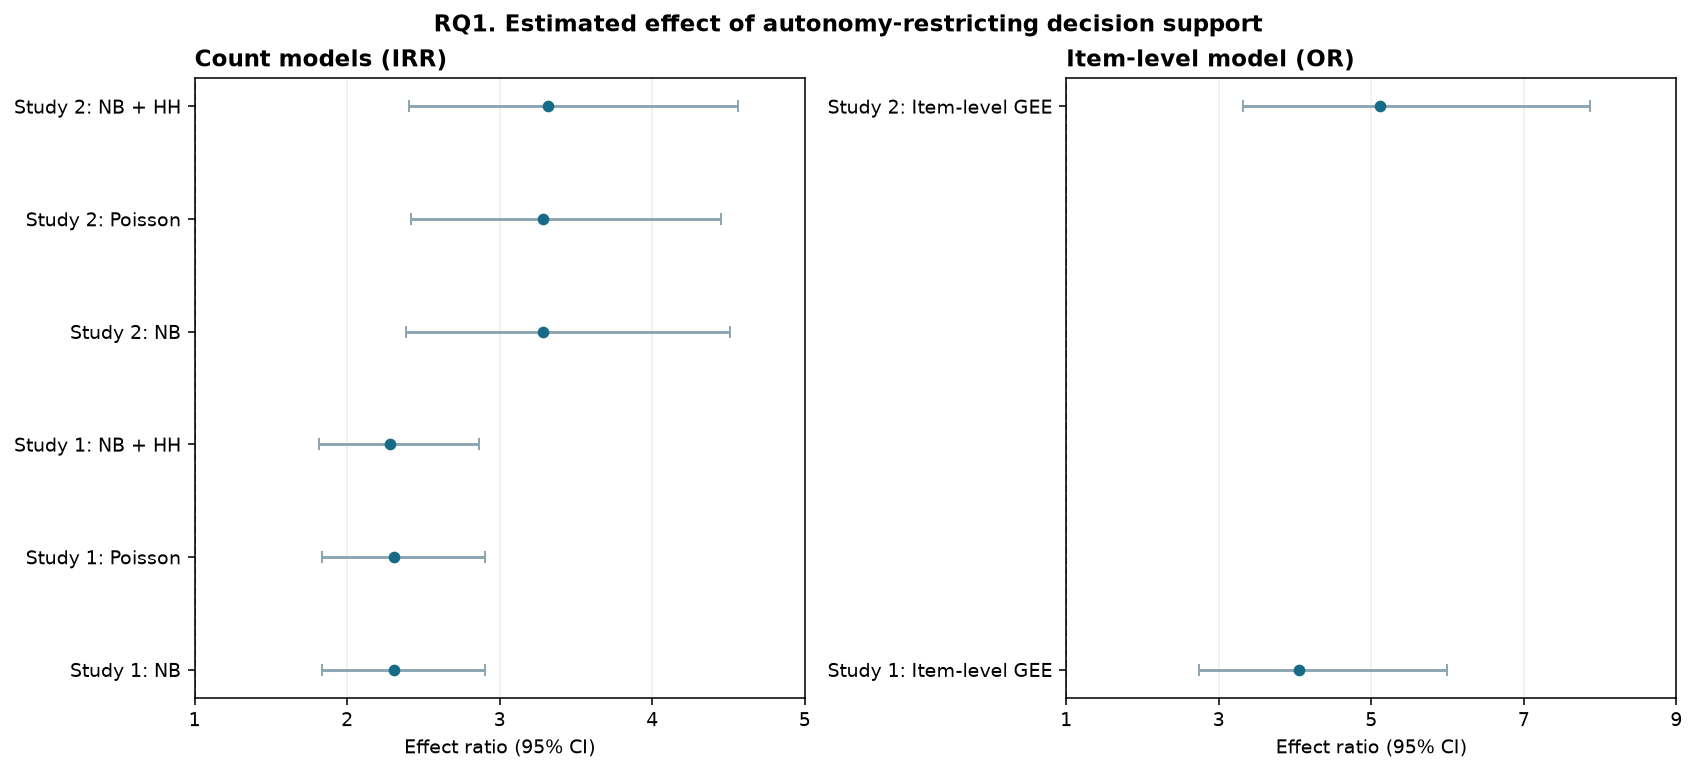

In [3]:
# What this cell does: fits alternative count and item-level models for the randomized condition.
# Main step / RQ1: compare effect direction, size, and uncertainty across model families.
def model_row(study, model, fit, term, scale, n):
    b, se = float(fit.params[term]), float(fit.bse[term])
    return {'Study':study, 'Specification':model, 'Scale':scale, 'N':n,
            'Estimate':np.exp(b), 'CI lower':np.exp(b-1.96*se),
            'CI upper':np.exp(b+1.96*se), 'p value':float(fit.pvalues[term])}

rq1_rows=[]
for label, d in [('Study 1',s1),('Study 2',s2)]:
    fit=smf.negativebinomial('UnethicalCount ~ restricted',data=d).fit(disp=False,maxiter=200)
    rq1_rows.append(model_row(label,'Negative binomial',fit,'restricted','IRR',len(d)))
    fit=smf.glm('UnethicalCount ~ restricted',data=d,family=sm.families.Poisson()).fit(cov_type='HC0')
    rq1_rows.append(model_row(label,'Poisson, robust SE',fit,'restricted','IRR',len(d)))
    if 'HonestyHumility' in d and d['HonestyHumility'].notna().sum()==len(d):
        fit=smf.negativebinomial('UnethicalCount ~ restricted + HonestyHumility',data=d).fit(disp=False,maxiter=200)
        rq1_rows.append(model_row(label,'Negative binomial + honesty-humility',fit,'restricted','IRR',len(d)))
    long=d[['participant_id','restricted']+ITEMS].melt(id_vars=['participant_id','restricted'],
             value_vars=ITEMS,var_name='item',value_name='choice').dropna()
    long['item']=long['item'].map(dict(zip(ITEMS,ITEM_LABELS)))
    fit=GEE.from_formula('choice ~ restricted + C(item)',groups='participant_id',data=long,
                         family=Binomial(),cov_struct=Exchangeable()).fit()
    rq1_rows.append(model_row(label,'Item logistic GEE, item fixed effects',fit,'restricted','OR',len(long)))
rq1_results=pd.DataFrame(rq1_rows)
rq1_results.to_csv(RESULT_DIR/'rq1_model_robustness.csv',index=False)
display(rq1_results.round(3))

fig, axes=plt.subplots(1,2,figsize=(12,5.4),constrained_layout=True)
short_names={'Negative binomial':'NB','Poisson, robust SE':'Poisson','Negative binomial + honesty-humility':'NB + HH','Item logistic GEE, item fixed effects':'Item-level GEE'}
for ax,scale,title,xlim,xticks in zip(axes,['IRR','OR'],['Count models (IRR)','Item-level model (OR)'],[(1,5),(1,9)],[[1,2,3,4,5],[1,3,5,7,9]]):
    z=rq1_results[rq1_results.Scale==scale].reset_index(drop=True)
    y=np.arange(len(z))
    ax.errorbar(z.Estimate,y,xerr=[z.Estimate-z['CI lower'],z['CI upper']-z.Estimate],
                fmt='o',color='#176B87',ecolor='#8AA6B2',capsize=3,markersize=5)
    ax.axvline(1,color='#4B5563',linestyle='--',linewidth=1)
    ax.set_yticks(y,[f"{r['Study']}: {short_names[r['Specification']]}" for _,r in z.iterrows()])
    ax.set_xlim(*xlim); ax.set_xticks(xticks); ax.set_xlabel('Effect ratio (95% CI)'); ax.set_title(title,loc='left',fontweight='bold')
    ax.grid(axis='x',alpha=.2)
fig.suptitle('RQ1. Estimated effect of autonomy-restricting decision support',fontweight='bold')
fig.savefig(RESULT_DIR/'figure1_rq1_robustness.png',dpi=300,bbox_inches='tight')
fig.savefig(RESULT_DIR/'figure1_rq1_robustness.pdf',bbox_inches='tight')
display(fig)

## 4. RQ2 — Compare maximum and actor-specific responsibility ratings

Study 2 asks participants to rate responsibility for themselves, managers/executives, SmartAnswer, and its designers. The published external-attribution summary is the maximum across the three external actors. This step recomputes that maximum and compares condition means with each actor’s rating separately at T1 and T2.

Time,Actor summary,Restricted n,Affording n,Restricted mean,Affording mean,Difference (restricted - affording),95% CI lower,95% CI upper
T1,Self,132,124,2.788,3.363,-0.575,-0.844,-0.307
T1,Managers / executives,132,124,3.523,3.032,0.490,0.223,0.758
T1,Algorithm,132,124,3.227,2.581,0.647,0.375,0.919
T1,Designers,132,124,3.371,2.734,0.637,0.372,0.903
T1,Maximum external actor,132,124,3.992,3.387,0.605,0.365,0.846
T2,Self,132,124,2.758,3.411,-0.654,-0.922,-0.386
T2,Managers / executives,132,124,3.682,3.032,0.650,0.386,0.913
T2,Algorithm,132,124,3.371,2.734,0.637,0.359,0.915
T2,Designers,132,124,3.386,2.694,0.693,0.430,0.955
T2,Maximum external actor,132,124,4.061,3.347,0.714,0.476,0.952


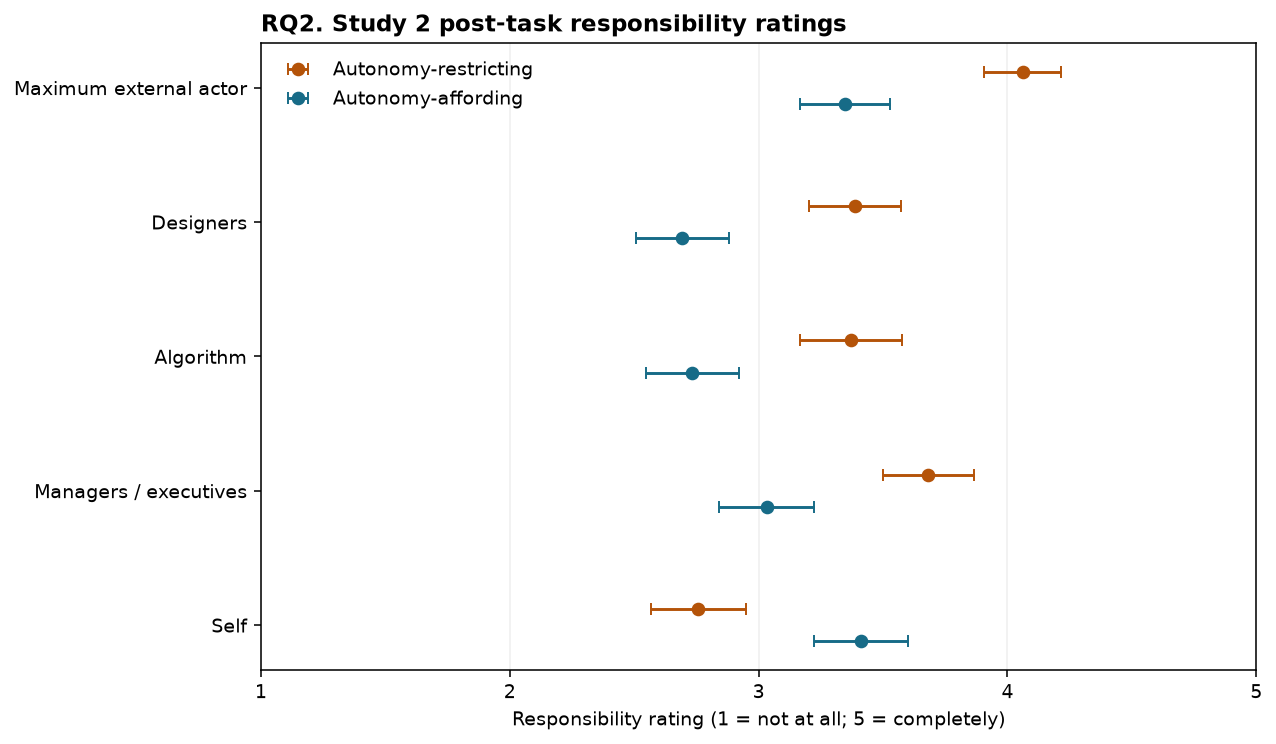

In [4]:
# What this cell does: summarizes responsibility ratings for each actor and the external maximum.
# Main step / RQ2: test whether the maximum summary hides actor-specific patterns.
ACTORS={
 'Self':'T{t}NCThemselves',
 'Managers / executives':'T{t}NCExecs',
 'Algorithm':'T{t}NCAlgorithm',
 'Designers':'T{t}NCDesigner'}
actor_data=[]
for t in ['1','2']:
    for actor,template in ACTORS.items():
        actor_data.append((f'T{t}',actor,s2[template.format(t=t)]))
    ext=s2[[f'T{t}NCDesigner',f'T{t}NCAlgorithm',f'T{t}NCExecs']].max(axis=1)
    actor_data.append((f'T{t}','Maximum external actor',ext))

def group_contrast(values,condition):
    x=np.asarray(values,dtype=float); g=np.asarray(condition,dtype=int)
    a=x[g==1]; b=x[g==0]; a=a[np.isfinite(a)]; b=b[np.isfinite(b)]
    diff=a.mean()-b.mean(); se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
    return len(a),len(b),a.mean(),b.mean(),diff,diff-1.96*se,diff+1.96*se
actor_rows=[]
for time,actor,values in actor_data:
    nlow,nhigh,mlow,mhigh,diff,lo,hi=group_contrast(values,s2.restricted)
    actor_rows.append({'Time':time,'Actor summary':actor,'Restricted n':nlow,'Affording n':nhigh,
                       'Restricted mean':mlow,'Affording mean':mhigh,'Difference (restricted - affording)':diff,
                       '95% CI lower':lo,'95% CI upper':hi})
actor_results=pd.DataFrame(actor_rows)
actor_results.to_csv(RESULT_DIR/'rq2_actor_responsibility.csv',index=False)
display(actor_results.round(3))

plot_rows=actor_results[actor_results.Time=='T2'].reset_index(drop=True)
fig,ax=plt.subplots(figsize=(9,5.2),constrained_layout=True)
y=np.arange(len(plot_rows)); offset=.12
for cond,label,color,mean_col in [(1,'Autonomy-restricting','#B45309','Restricted mean'),(0,'Autonomy-affording','#176B87','Affording mean')]:
    vals=[]
    for _,r in plot_rows.iterrows():
        values=s2[r['Actor summary']] if r['Actor summary'] in s2.columns else s2[['T2NCDesigner','T2NCAlgorithm','T2NCExecs']].max(axis=1)
        if r['Actor summary']=='Self': values=s2['T2NCThemselves']
        elif r['Actor summary']=='Managers / executives': values=s2['T2NCExecs']
        elif r['Actor summary']=='Algorithm': values=s2['T2NCAlgorithm']
        elif r['Actor summary']=='Designers': values=s2['T2NCDesigner']
        sub=values[s2.restricted==cond].dropna(); vals.append((sub.mean(),1.96*sub.std(ddof=1)/np.sqrt(len(sub))))
    means=np.array([v[0] for v in vals]); errs=np.array([v[1] for v in vals])
    ax.errorbar(means,y+(offset if cond else -offset),xerr=errs,fmt='o',label=label,color=color,capsize=3)
ax.set_yticks(y,plot_rows['Actor summary']); ax.set_xlim(1,5); ax.set_xticks([1,2,3,4,5]);
ax.set_xlabel('Responsibility rating (1 = not at all; 5 = completely)')
ax.set_title('RQ2. Study 2 post-task responsibility ratings',loc='left',fontweight='bold'); ax.legend(frameon=False)
ax.grid(axis='x',alpha=.2)
fig.savefig(RESULT_DIR/'figure2_rq2_actor_attribution.png',dpi=300,bbox_inches='tight')
fig.savefig(RESULT_DIR/'figure2_rq2_actor_attribution.pdf',bbox_inches='tight')
display(fig)

## 5. RQ3 — Estimate effects by dilemma and study

This step reports each dilemma’s unethical-choice proportion in each randomized condition, with Wilson confidence intervals. It also reports the restricted-minus-affording risk difference for each dilemma. The four shared dilemma items are retained and analyzed separately; comparisons across studies are descriptive because the task context was not identical in every respect.

Study,Dilemma,Restricted n,Restricted unethical %,Restricted CI lower %,Restricted CI upper %,Affording n,Affording unethical %,Affording CI lower %,Affording CI upper %,Risk difference pp (restricted - affording),RD CI lower pp,RD CI upper pp
Study 1,Booking fee,136,55.1,46.8,63.3,140,25.7,19.2,33.5,29.4,18.4,40.5
Study 1,Checkout,136,69.9,61.7,76.9,140,45.0,37.0,53.3,24.9,13.6,36.1
Study 1,Points,136,47.8,39.6,56.1,140,12.1,7.7,18.6,35.7,25.7,45.6
Study 1,Wrong room,136,43.4,35.3,51.8,140,10.7,6.6,16.9,32.7,22.9,42.4
Study 2,Booking fee,132,53.0,44.6,61.3,124,21.8,15.4,29.8,31.3,20.1,42.4
Study 2,Checkout,132,57.6,49.0,65.7,124,21.8,15.4,29.8,35.8,24.7,46.9
Study 2,Points,132,38.6,30.8,47.2,124,4.8,2.2,10.2,33.8,24.7,42.9
Study 2,Wrong room,132,33.3,25.9,41.7,124,7.3,3.9,13.2,26.1,16.8,35.3


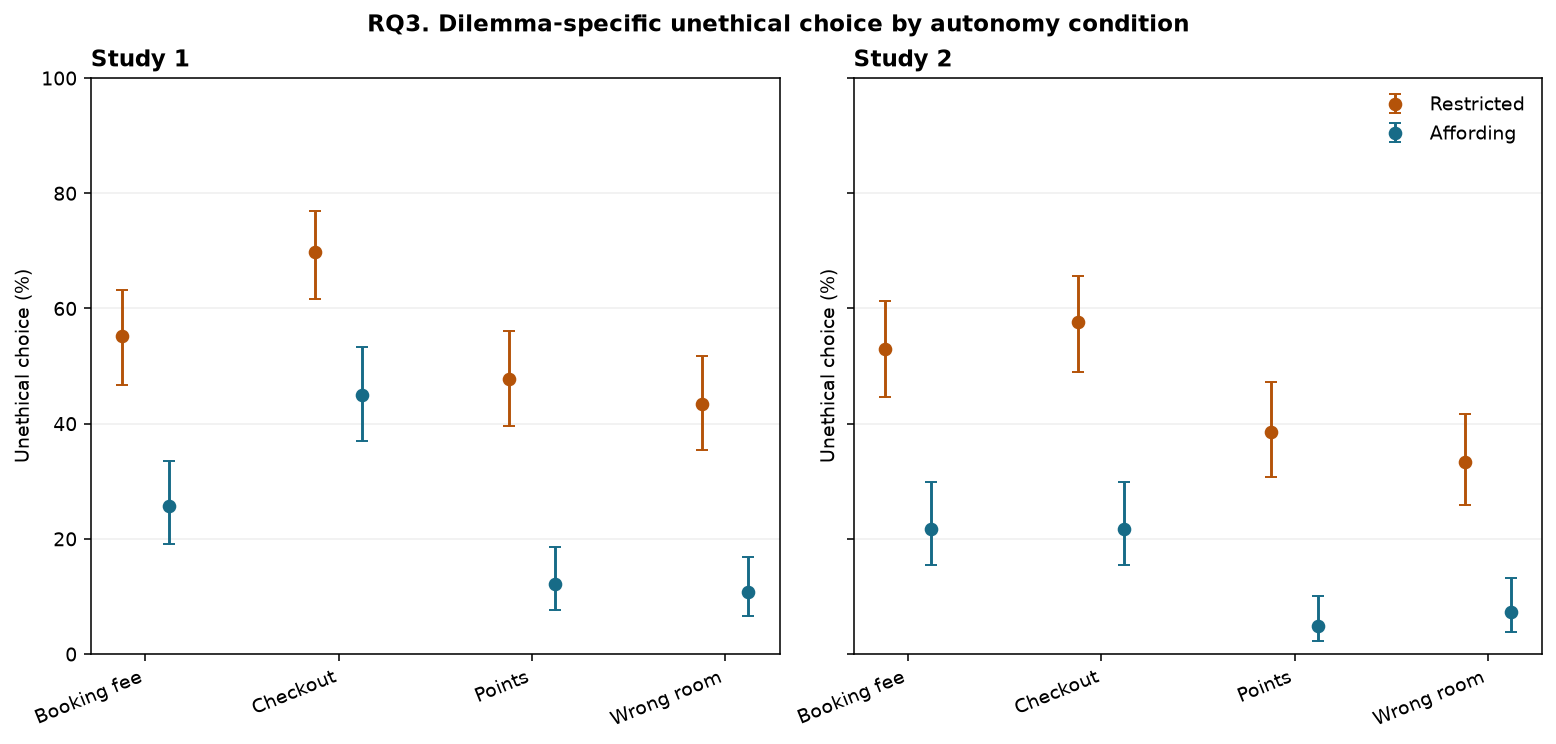

In [5]:
# What this cell does: estimates item-level choice rates and condition risk differences.
# Main step / RQ3: display dilemma-specific patterns and compare them across studies.
def wilson(k,n,z=1.96):
    if n==0: return np.nan,np.nan
    p=k/n; den=1+z*z/n; center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half
rq3_rows=[]
for label,d in [('Study 1',s1),('Study 2',s2)]:
    for item,item_label in zip(ITEMS,ITEM_LABELS):
        by={}
        for cond,cond_label in [(1,'Restricted'),(0,'Affording')]:
            vals=d.loc[d.restricted==cond,item].dropna().astype(int); n=len(vals); k=int(vals.sum())
            lo,hi=wilson(k,n); by[cond]=(n,k,k/n,lo,hi)
        n1,k1,p1,lo1,hi1=by[1]; n0,k0,p0,lo0,hi0=by[0]
        diff=p1-p0; se=np.sqrt(p1*(1-p1)/n1+p0*(1-p0)/n0)
        rq3_rows.append({'Study':label,'Dilemma':item_label,'Restricted n':n1,'Restricted unethical %':100*p1,
                         'Restricted CI lower %':100*lo1,'Restricted CI upper %':100*hi1,
                         'Affording n':n0,'Affording unethical %':100*p0,
                         'Affording CI lower %':100*lo0,'Affording CI upper %':100*hi0,
                         'Risk difference pp (restricted - affording)':100*diff,
                         'RD CI lower pp':100*(diff-1.96*se),'RD CI upper pp':100*(diff+1.96*se)})
rq3_results=pd.DataFrame(rq3_rows)
rq3_results.to_csv(RESULT_DIR/'rq3_dilemma_effects.csv',index=False)
display(rq3_results.round(1))

fig,axes=plt.subplots(1,2,figsize=(11,5.2),sharey=True,constrained_layout=True)
for ax,(label,d) in zip(axes,[('Study 1',s1),('Study 2',s2)]):
    z=rq3_results[rq3_results.Study==label].reset_index(drop=True); x=np.arange(len(z)); width=.18
    for cond,series,color,shift in [('Restricted','Restricted unethical %','#B45309',-width/1.5),('Affording','Affording unethical %','#176B87',width/1.5)]:
        mean=z[f'{series}']; lo=z['Restricted CI lower %' if series=='Restricted unethical %' else 'Affording CI lower %']; hi=z['Restricted CI upper %' if series=='Restricted unethical %' else 'Affording CI upper %']
        ax.errorbar(x+shift,mean,yerr=[mean-lo,hi-mean],fmt='o',capsize=3,label=cond,color=color)
    ax.set_xticks(x,z.Dilemma,rotation=22,ha='right'); ax.set_ylim(0,100); ax.set_ylabel('Unethical choice (%)')
    ax.set_title(label,loc='left',fontweight='bold'); ax.grid(axis='y',alpha=.2)
axes[1].legend(frameon=False,loc='upper right')
fig.suptitle('RQ3. Dilemma-specific unethical choice by autonomy condition',fontweight='bold')
fig.savefig(RESULT_DIR/'figure3_rq3_dilemma_effects.png',dpi=300,bbox_inches='tight')
fig.savefig(RESULT_DIR/'figure3_rq3_dilemma_effects.pdf',bbox_inches='tight')
display(fig)

## 6. RQ4 — Assess measurement and mediation sensitivity

For each mediator definition, the notebook estimates the condition-to-mediator path and the mediator association with the unethical-choice count conditional on condition using a negative-binomial outcome model. It bootstraps participants for a percentile interval around the product-of-coefficients index. The three specifications are the Study 1 broad responsibility composite, Study 2 self-responsibility rating, and Study 2 maximum external-actor rating. Because the mediator was not randomized, these indices are descriptive sensitivity results rather than identified causal mediation effects.

Study,Mediator operationalization,N,a path: condition → mediator,b path: mediator → count (NB log scale),Product index a × b,Bootstrap 95% lower,Bootstrap 95% upper,Completed draws; convergence not audited
Study 1,Broad responsibility (T1 composite),276,-0.476,-0.092,0.044,-0.027,0.113,1000
Study 2,Self-responsibility (T1),256,-0.575,-0.145,0.083,0.015,0.190,1000
Study 2,Maximum external actor (T1),256,0.605,0.039,0.024,-0.067,0.120,1000


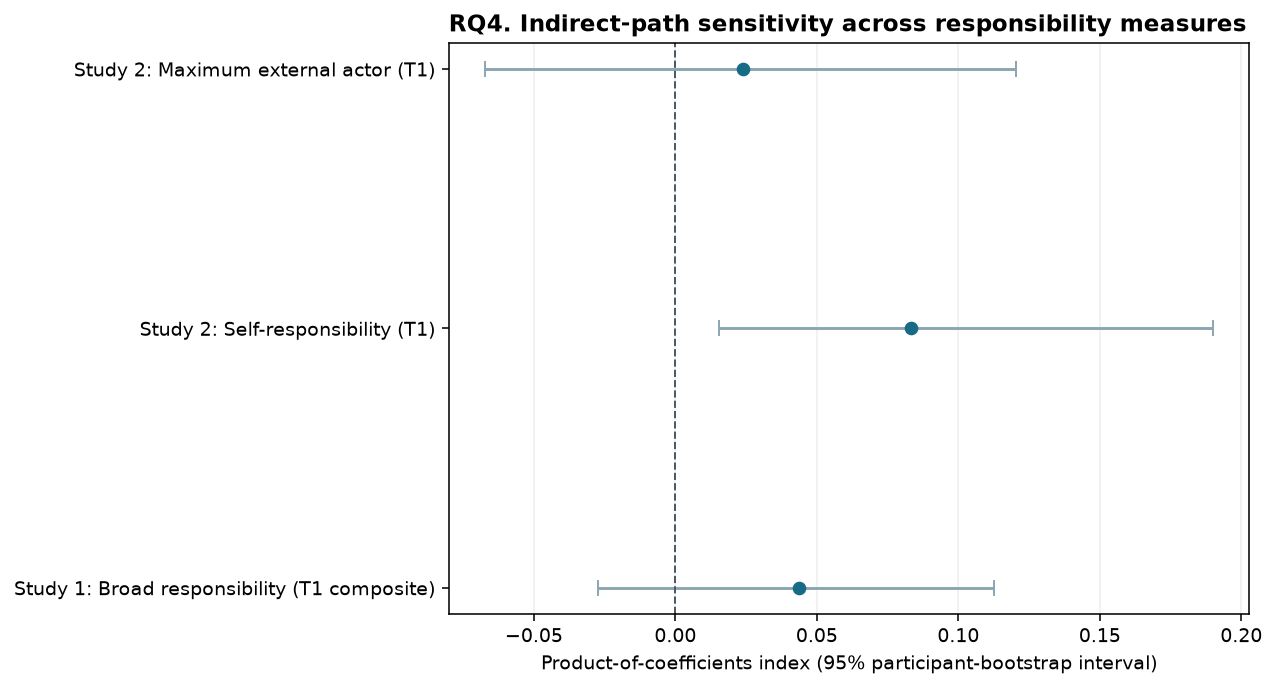

In [6]:
# What this cell does: bootstraps indirect-path indices under alternative responsibility measures.
# Main step / RQ4: show how mediator definition and model assumptions change the inferred path.
MEDIATORS=[
    ('Study 1','Broad responsibility (T1 composite)',s1,'responsibility_t1',True),
    ('Study 2','Self-responsibility (T1)',s2,'responsibility_t1',False),
    ('Study 2','Maximum external actor (T1)',s2,'external_max_t1',False)]

def mediation_paths(d, mediator, adjust_hh=False):
    x=d[['restricted','UnethicalCount',mediator]+(['HonestyHumility'] if adjust_hh else [])].dropna().copy()
    x=x.rename(columns={mediator:'mediator'})
    a_fit=smf.ols('mediator ~ restricted',data=x).fit()
    formula='UnethicalCount ~ restricted + mediator' + (' + HonestyHumility' if adjust_hh else '')
    b_fit=smf.negativebinomial(formula,data=x).fit(disp=False,maxiter=150)
    return float(a_fit.params['restricted']),float(b_fit.params['mediator']),len(x)

B=1000
med_rows=[]
for j,(study,label,d,mediator,hh) in enumerate(MEDIATORS):
    a,b,n=mediation_paths(d,mediator,hh); rng=np.random.default_rng(20261102+j); draws=[]
    x=d[['restricted','UnethicalCount',mediator]+(['HonestyHumility'] if hh else [])].dropna().reset_index(drop=True)
    for k in range(B):
        sample=x.iloc[rng.integers(0,len(x),len(x))].reset_index(drop=True)
        try:
            aa,bb,_=mediation_paths(sample,mediator,hh); draws.append(aa*bb)
        except Exception:
            continue
    lo,hi=np.quantile(draws,[.025,.975])
    med_rows.append({'Study':study,'Mediator operationalization':label,'N':n,'a path: condition → mediator':a,
                     'b path: mediator → count (NB log scale)':b,'Product index a × b':a*b,
                     'Bootstrap 95% lower':lo,'Bootstrap 95% upper':hi,'Completed draws; convergence not audited':len(draws)})
rq4_results=pd.DataFrame(med_rows)
rq4_results.to_csv(RESULT_DIR/'rq4_mediation_sensitivity.csv',index=False)
display(rq4_results.round(3))

fig,ax=plt.subplots(figsize=(9,4.8),constrained_layout=True)
y=np.arange(len(rq4_results)); est=rq4_results['Product index a × b']; lo=rq4_results['Bootstrap 95% lower']; hi=rq4_results['Bootstrap 95% upper']
ax.errorbar(est,y,xerr=[est-lo,hi-est],fmt='o',color='#176B87',ecolor='#8AA6B2',capsize=4)
ax.axvline(0,color='#4B5563',linestyle='--',linewidth=1); ax.set_yticks(y,[f"{r.Study}: {r['Mediator operationalization']}" for _,r in rq4_results.iterrows()])
ax.set_xlabel('Product-of-coefficients index (95% participant-bootstrap interval)')
ax.set_title('RQ4. Indirect-path sensitivity across responsibility measures',loc='left',fontweight='bold'); ax.grid(axis='x',alpha=.2)
fig.savefig(RESULT_DIR/'figure4_rq4_mediation_sensitivity.png',dpi=300,bbox_inches='tight')
fig.savefig(RESULT_DIR/'figure4_rq4_mediation_sensitivity.pdf',bbox_inches='tight')
display(fig)

## 7. Save and package the publication outputs

This final step writes an interpretation note and packages every generated CSV table and PDF/PNG figure into one ZIP archive. Review model diagnostics, coding, the original syntax, and OSF reuse terms before treating any result as a manuscript result.

In [7]:
# What this cell does: writes a results guide and bundles every table and figure.
# Main step: create the requested ZIP archive for download or manuscript preparation.
readme = """Project 16 analysis outputs

RQ1: rq1_model_robustness.csv; figure1_rq1_robustness.(png/pdf)
RQ2: rq2_actor_responsibility.csv; figure2_rq2_actor_attribution.(png/pdf)
RQ3: rq3_dilemma_effects.csv; figure3_rq3_dilemma_effects.(png/pdf)
RQ4: rq4_mediation_sensitivity.csv; figure4_rq4_mediation_sensitivity.(png/pdf)
data_audit.csv: analytic sample and outcome reconciliation.

The supplied SPSS files contain final analytic samples only; participant-screening sensitivity cannot be assessed for excluded cases. Indirect-path estimates are assumption-dependent and not causal mediation effects. Confirm reuse terms before redistribution/publication.
"""
(RESULT_DIR/'README.txt').write_text(readme,encoding='utf-8')
import zipfile
zip_path=Path.cwd()/'project16_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(RESULT_DIR.iterdir()):
        if f.is_file(): z.write(f,arcname=f.name)
print(f'Created {len(list(RESULT_DIR.iterdir()))} result files in {RESULT_DIR}')
print(f'ZIP archive: {zip_path} ({zip_path.stat().st_size:,} bytes)')

Created 14 result files in /Users/fiona/Documents/Codex/2026-11-02/referenced-chatgpt-conversation-this-is-an/work/project16_results
ZIP archive: /Users/fiona/Documents/Codex/2026-11-02/referenced-chatgpt-conversation-this-is-an/work/project16_results.zip (465,216 bytes)
